In [2]:
from mplsoccer import Pitch
from utils.plotting import plot_event
import matplotlib.pyplot as plt
import os
import pandas as pd
import seaborn as sns

In [3]:
events_df = pd.concat(
    [pd.read_parquet(f"../data/{df}") for df in os.listdir("../data") if df.endswith(".parquet")]
)

In [3]:
carry_pass_shot_events_df = events_df[events_df["type"].isin(["Pass", "Carry", "Shot"])]

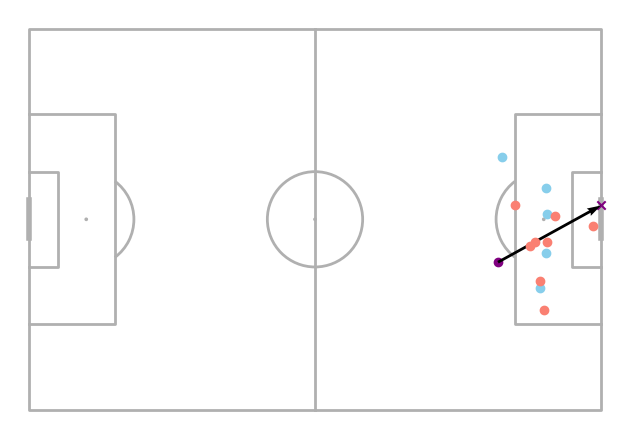

In [19]:
plot_event(
    df=carry_pass_shot_events_df, 
    event_id="45a21d64-ccc8-4007-b9c8-fb3f6992dace"
)

plt.tight_layout()
plt.show()

In [6]:
df = carry_pass_shot_events_df[
    (carry_pass_shot_events_df["type_name"] != "Pass") | 
    (carry_pass_shot_events_df["pass_outcome"].isna())  # successful only
]

In [7]:
df["start_x"] = df["location"].apply(lambda x: x[0] if isinstance(x, list) else None)
df["start_y"] = df["location"].apply(lambda x: x[1] if isinstance(x, list) else None)

<positron-console-cell-7>:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
<positron-console-cell-7>:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
<positron-console-cell-7>:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
<positron-console-cell-7>:2: SettingWithCopyWarning: 
A value is trying

In [8]:
def get_end_location(row):
    if row["type_name"] == "Pass":
        return row["pass_end_location"]
    elif row["type_name"] == "Carry":
        return row["carry_end_location"]
    elif row["type_name"] == "Shot":
        return row["shot_end_location"]
    return None

df["end_location"] = df.apply(get_end_location, axis=1)

df["end_x"] = df["end_location"].apply(lambda x: x[0] if isinstance(x, list) else None)
df["end_y"] = df["end_location"].apply(lambda x: x[1] if isinstance(x, list) else None)

<positron-console-cell-8>:10: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
<positron-console-cell-8>:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
<positron-console-cell-8>:12: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
<positron-console-cell-8>:12: SettingWithCopyWarning: 
A value is tr

In [9]:
df["action_type"] = df["type_name"].str.lower()

<positron-console-cell-9>:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
<positron-console-cell-9>:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy


In [10]:
import socceraction.xthreat as xthreat
url_grid = "https://karun.in/blog/data/open_xt_12x8_v1.json"
xT_model = xthreat.load_model(url_grid)

In [13]:
grid = xT_model.xT
l, w = xT_model.l, xT_model.w

In [14]:
import numpy as np

def get_xT(x, y, model):
    if np.isnan(x) or np.isnan(y):
        return np.nan

    l, w = model.l, model.w

    # clamp to pitch
    x = max(0, min(120, x))
    y = max(0, min(80, y))

    x_bin = int(x / (120 / l))
    y_bin = int(y / (80 / w))

    # avoid overflow
    x_bin = min(x_bin, l - 1)
    y_bin = min(y_bin, w - 1)

    return model.xT[y_bin, x_bin]

In [15]:
df["xT_start"] = df.apply(
    lambda r: get_xT(r["start_x"], r["start_y"], xT_model),
    axis=1
)

df["xT_end"] = df.apply(
    lambda r: get_xT(r["end_x"], r["end_y"], xT_model),
    axis=1
)

df["xT_value"] = df["xT_end"] - df["xT_start"]

<positron-console-cell-15>:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
<positron-console-cell-15>:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
<positron-console-cell-15>:6: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
<positron-console-cell-15>:6: SettingWithCopyWarning: 
A value is tr

In [17]:
df["action_value"] = df["xT_value"]
df = df.reset_index(drop=True)
df = df.copy()
df.loc[df["action_type"] == "shot", "action_value"] = df["shot_statsbomb_xg"]

<positron-console-cell-17>:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy


In [ ]:
def generate_pass_counterfactuals(row, xT_model):
    start = [row["start_x"], row["start_y"]]
    teammates = row["teammates"]
    opponents = row["opponents"]

    options = []

    for mate in teammates:
        end = mate["location"]

        # Skip actor (just in case)
        if end == start:
            continue

        # Distance filter
        dist = distance(start, end)
        if dist < 2 or dist > 40:
            continue

        # Passing lane check
        if is_pass_blocked(start, end, opponents):
            continue

        # Compute xT
        xT_start = get_xT(start[0], start[1], xT_model)
        xT_end = get_xT(end[0], end[1], xT_model)

        value = xT_end - xT_start

        options.append({
            "action": "pass",
            "target": end,
            "distance": dist,
            "value": value
        })

    return options